# Lab 3
Katherine Merrill

PHYS 434 AB

10-21-2026

# Problem 1
Simulating 100k good data points assuming Gaussian fluctuations and adding bad data points at: {10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7}:

mean $\mu$ = 12 K, 
SD $\sigma$ = 0.4 K

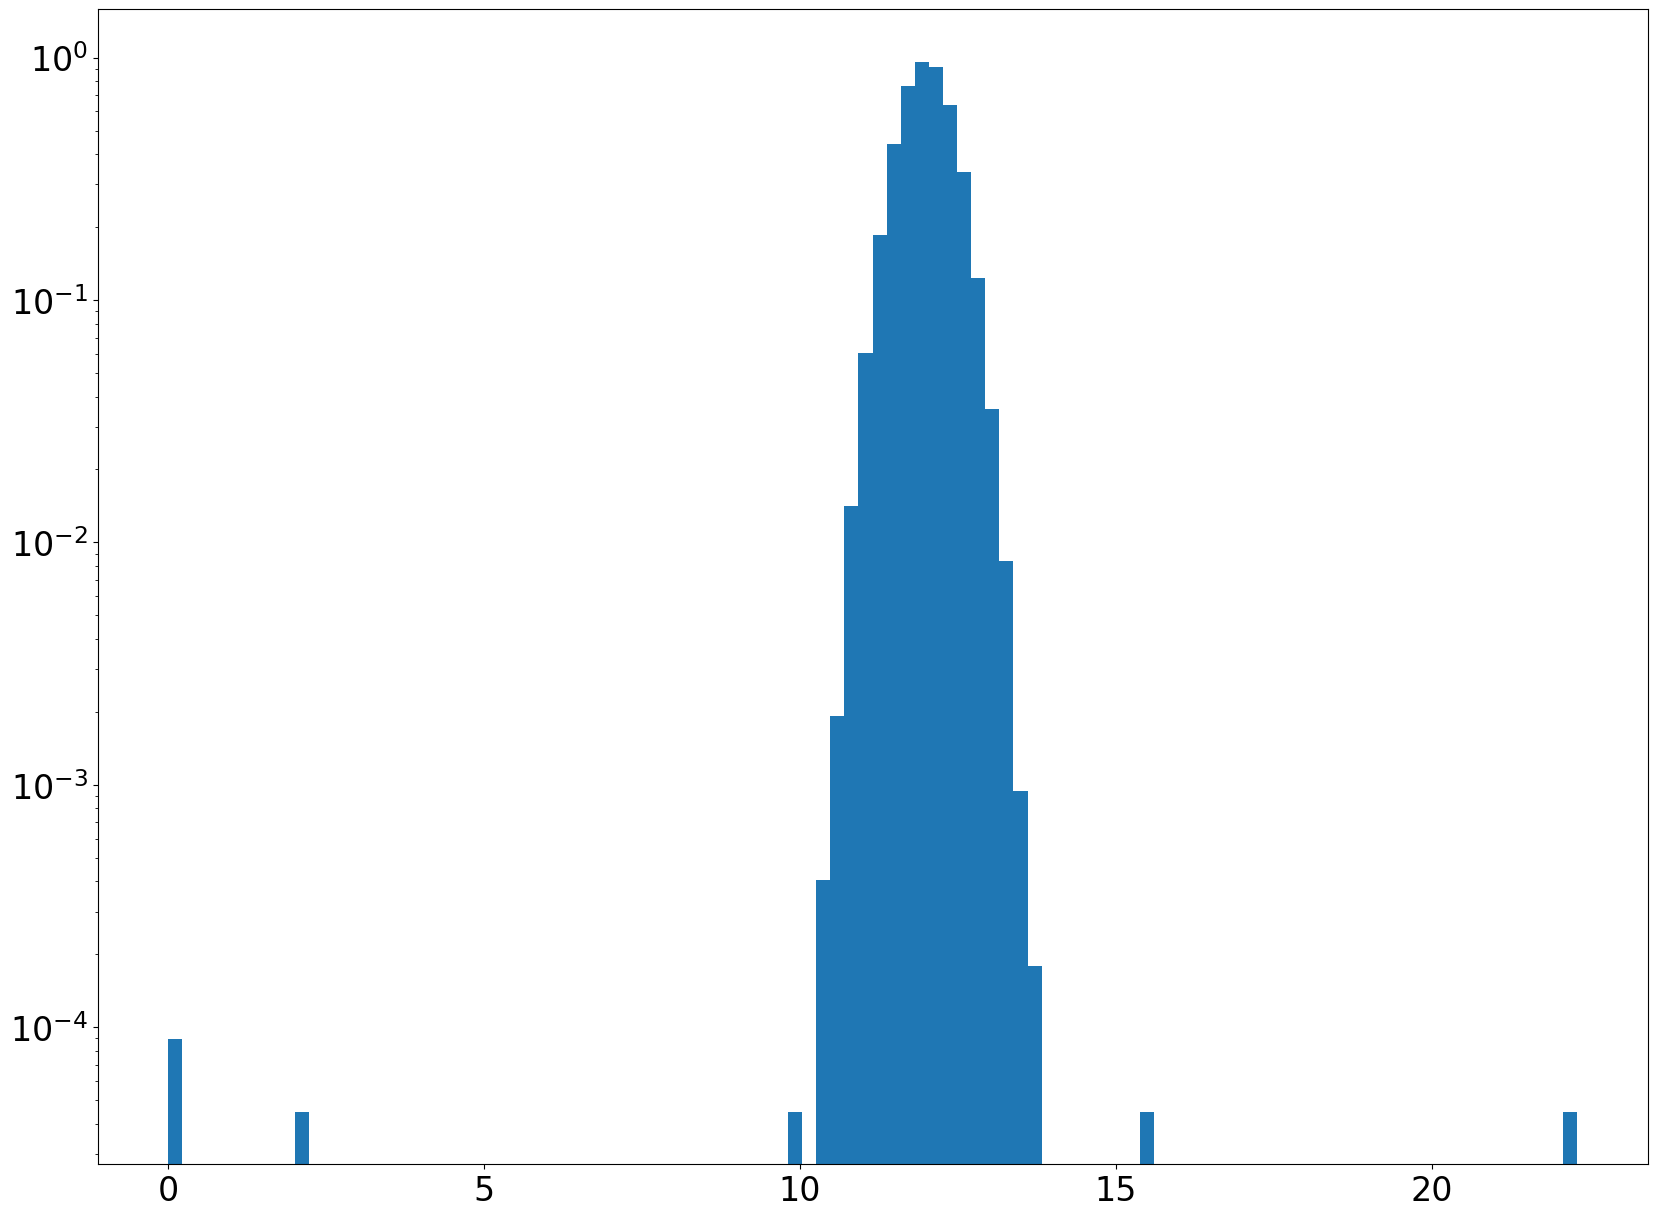

In [40]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import pandas

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

## Part A
#### 1) State the statistical question in words:

If a reading came from the good distribution N(12 K, 0.4 K), how likely is a reading at least this far from 12 K in either direction? 

#### 2) Restate in math:

For a reading T with a z-score of z = (T − 12)/0.4 standard deviations away from the mean, what is the probability p = 2·sf(|z|)?

#### 3) Apply your statistical test and construct a truth table.

For a threshold k=4:

In [41]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])

mu=12
sigma=0.4
k = 4                         
z = np.abs(d - mu) / sigma       

subset = d[z > k]               
print("Readings thrown out:", np.sort(subset))
print("How many:", len(subset))

Readings thrown out: [ 0.          0.          2.1         9.88297089 10.         10.3
 10.33253876 10.35037187 10.36012984 13.68855098 15.6        22.3       ]
How many: 12


Truth table for k=4 as the statistical threshold:
| | True Good :)| True Bad :(|
| :---     | :---:    | ---:     |
| Test Good :)    | 99,996   | 1  |
| Test Bad :(    | 4  | 7   |


## B) How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

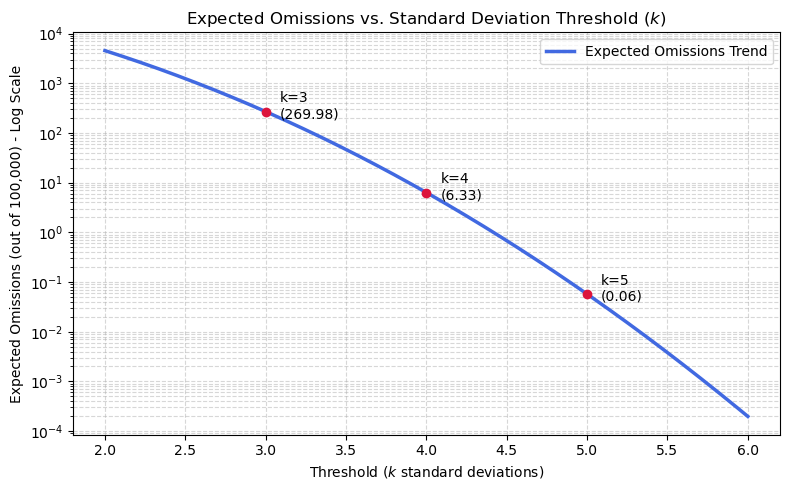

In [42]:
n_good = 100_000
k_continuous = np.linspace(2, 6, 500)
p_omit_continuous = 2 * stats.norm.sf(k_continuous)
expected_continuous = n_good * p_omit_continuous

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_continuous, expected_continuous, label="Expected Omissions Trend", color="royalblue", linewidth=2.5)
for k in [3, 4, 5]:
    p_k = 2 * stats.norm.sf(k)
    ax.scatter(k, n_good * p_k, color="crimson", zorder=5)
    ax.annotate(f"k={k}\n({n_good * p_k:.2f})", (k, n_good * p_k), textcoords="offset points", xytext=(10,-5), ha='left')
ax.set_yscale('log') # Log scale is recommended because the values drop so drastically
ax.set_title("Expected Omissions vs. Standard Deviation Threshold ($k$)")
ax.set_xlabel("Threshold ($k$ standard deviations)")
ax.set_ylabel("Expected Omissions (out of 100,000) - Log Scale")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

The chance of a good reading being omitted is $2sf(k)$, so for 100,000 good readings the expected omissions would be $200,000sf(k)$. As k increases, omissions should decrease steeply. The actual number comes from random data so its not really predictable but the average is predictable which is $2Nf(k)$ for N data points.

## C) Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

Yes. Commision occurs when the z-score is smaller than the threshold. Since each bad point has a fixed z, we can count how many bad points slip through at each threshold:


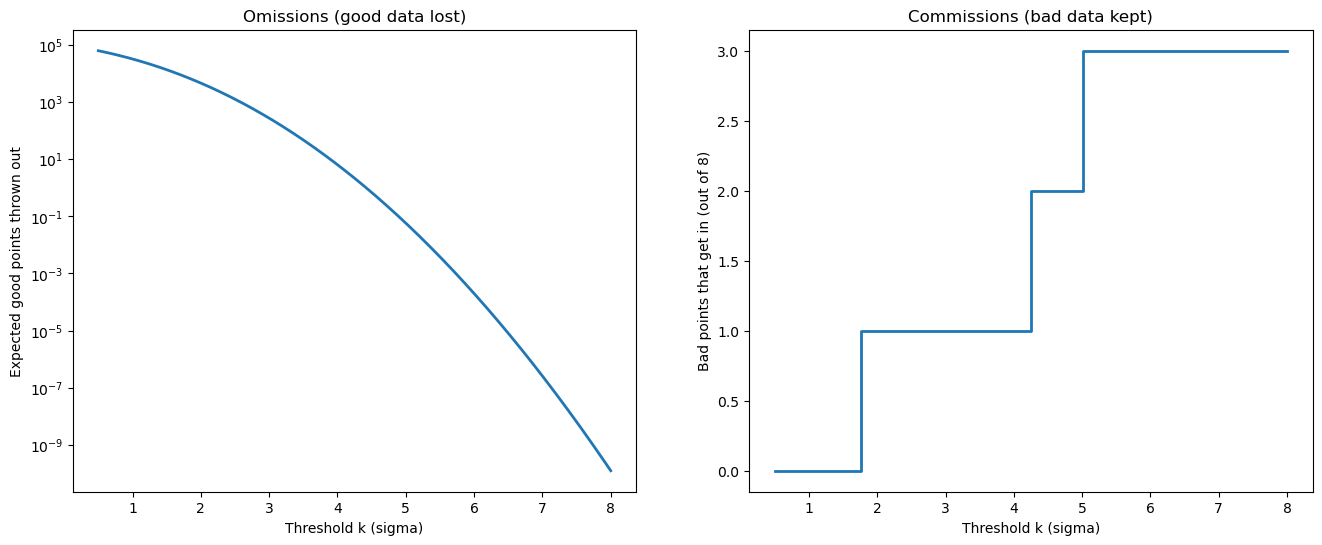

Bad points that got in at k = 4: [12.7] K


In [43]:
z_bad = np.abs(bad - mu) / sigma
k_fine = np.linspace(0.5, 8, 500)
n_bad_kept = np.array([np.sum(z_bad <= kk) for kk in k_fine])

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].semilogy(k_fine, n_good * 2 * stats.norm.sf(k_fine), lw=2)
ax[0].set_xlabel("Threshold k (sigma)")
ax[0].set_ylabel("Expected good points thrown out")
ax[0].set_title("Omissions (good data lost)")

ax[1].step(k_fine, n_bad_kept, where="post", lw=2)
ax[1].set_xlabel("Threshold k (sigma)")
ax[1].set_ylabel("Bad points that get in (out of 8)")
ax[1].set_title("Commissions (bad data kept)")
plt.show()

print("Bad points that got in at k = 4:", bad[z_bad <= 4], "K")

# Problem 2

The background distribution is a 2D gaussian with a 1 arcsecond RMS (which means $\sigma$=1 arcsecond too!)

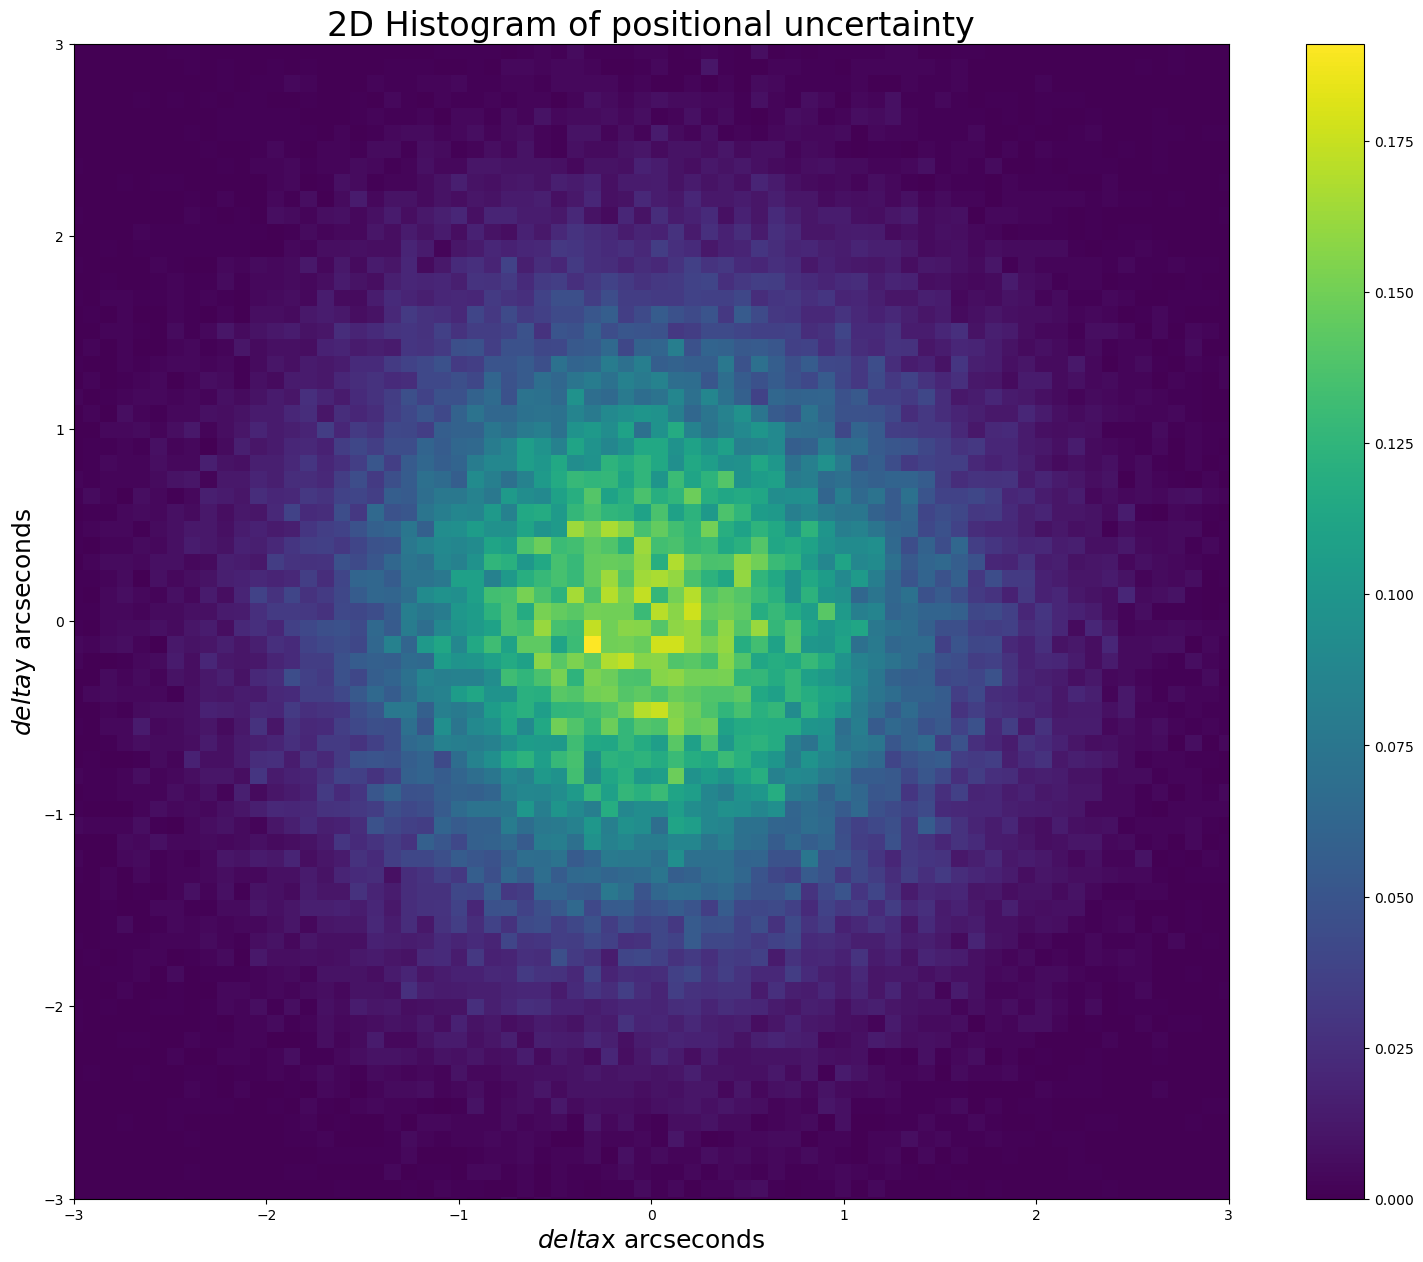

In [44]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import pandas
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$delta$y arcseconds", fontsize = 18)
plt.xlabel("$delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)


## Part 1: Question in words 
For a stationary star whose apparent shift is 2D Gaussian noise with 1 RMS per $\Delta y$ axis and $\Delta x$ axis, what distance r would give a probability of a false detection of movement that is equal to the 5-sigma tail of the 2d gaussian distribution? 

## Part 2: Question in math 
The distance a star appears to move will be $$r = \sqrt{\Delta x^2 + \Delta y^2}.$$ and from homework 3, the distribution of this distance will follow the Rayleigh distribution with pdf $$f(r) = \frac{r}{\sigma^2}\, e^{-r^2/(2\sigma^2)}, \qquad r \ge 0.$$ 

## Part 3: 5 sigma detection distance

Using norm.sf (5) to get the gaussian 5-sigma tail probability and then using rayleigh.isf(p) gives the distance that is associated with this probability:

In [45]:
p=stats.norm.sf(5)
r=stats.rayleigh.isf(p)
print (p)
print(r)

2.866515718791933e-07
5.489079776062419


so the distance is r=5.489079776062419 arcseconds

# Problem 3



## Part 1
What is the significance of the decrease in cosmic rays that are observed over 15 days due to the Moon being in the way? 
## Part 2 :
8h night x 60 min hour x 15 days=7200 min, 
7200 min x 1 cosmic ray/min = 7200 expected counts. The expected background pdf will be a Poisson distribution since its discrete (only integer values of yes/no if a cosmic ray observed) and the cosmic rays arrive independently of each other.



Since the sum of 2 poissons is also a Poisson, the cumulative probability of observing 6800 or fewer events in the Poisson distribution will be given by the cumulative distribution function for k=6800 and average $\mu$=7200:

stats.poisson.cdf(6800, 7200)


In [46]:
p_value = stats.poisson.cdf(6800, 7200)
print(p_value)

1.0133280183917768e-06


### Converting to sigma:
Using norm.isf(p) to find the Gaussian value with the same probability which will give the sigma value:


In [47]:
mu_bg = 7200      
n_obs = 6800                   

p_exact = stats.poisson.cdf(n_obs, mu_bg)     
sigma_exact = stats.norm.isf(p_exact)        
print (p_exact)
print (sigma_exact)

1.0133280183917768e-06
4.750747965777188



So the probability of seeing 6800 or fewer cosmic rays from background alone is 1.0133280183917768e-06 which is roughly 1 in a million. That is about 4.75 sigma using the exact Poisson calculation.

The unique aspect of this problem is that there was no look-elsewhere penalty. We knew in advance where the Moon is, so we only had to do one test. If we had searched the whole sky for any hole, we would have to account for the many places we could have looked. Additionally, the problem is unique beause it describes a
deficit, instead of an excess, so we looked at the lower tail, $P(N \le 6800)$, instead of the upper tail.
